# 01 - Exploratory data analysis: Olist sellers as supplier proxies
All tables come from the DuckDB model built by `make sql` (`sql/01..06`). Raw data is not committed - run `make data` first.

**Methodology note:** Olist marketplace sellers are used as *proxies* for suppliers.

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/olist.duckdb', read_only=True)

## Integrity and data-quality profile

In [2]:
json.load(open('artifacts/data_manifest.json'))

{'olist_orders_dataset.csv': {'rows': 99441,
  'sha256': '8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c91cec19ae3345ef9ecf',
  'bytes': 17654914},
 'olist_order_items_dataset.csv': {'rows': 112650,
  'sha256': '0bc4d068c4fe38cbb01bd90e8746e3c613fe7b4baef75fab7b0e329701c3e279',
  'bytes': 15438671},
 'olist_sellers_dataset.csv': {'rows': 3095,
  'sha256': '1f643d2b950373b85735e7794b20986f528d7a000432e7c6f9bcbb44d0846a0e',
  'bytes': 174703},
 'olist_customers_dataset.csv': {'rows': 99441,
  'sha256': '983a422239e1712ded753b3bf9ecf47dc73f144d306029dcfa99e70a226883d2',
  'bytes': 9033957},
 'olist_order_reviews_dataset.csv': {'rows': 99224,
  'sha256': '012b61c7593e34f51fa614efdf802b9c7056ce6aae5307ddb93236e7cfc797d7',
  'bytes': 14451670},
 'olist_products_dataset.csv': {'rows': 32951,
  'sha256': '3e6569628a17fbc75fd206ee357b59e20364b9afa90f5b6cd5b4d624c58aa9cc',
  'bytes': 2379446},
 'olist_order_payments_dataset.csv': {'rows': 103886,
  'sha256': '4f713964f2815dbbaa40b9488268c55aac362

In [3]:
con.execute('SELECT * FROM dq_report').df()

,check_name,n,total,detail
0,orders_rows,99441,99441.0,raw orders
1,order_items_rows,112650,112650.0,raw order items
2,sellers_rows,3095,3095.0,raw sellers
3,duplicate_order_id,0,99441.0,orders: duplicate keys
4,duplicate_item_key,0,112650.0,"items: duplicate (order_id, order_item_id)"
5,items_orphan_order,0,112650.0,items whose order is missing
6,items_orphan_seller,0,112650.0,items whose seller is missing
7,orders_without_items,775,99441.0,orders with no item rows
8,delivered_missing_delivery_ts,8,8.0,status delivered but no customer delivery time...
9,missing_approved_ts,160,99441.0,no approval timestamp


## Grain of the model

In [4]:
con.execute('''SELECT 'fct_items' t, COUNT(*) n FROM fct_items UNION ALL
SELECT 'fct_orders_delivered', COUNT(*) FROM fct_orders_delivered UNION ALL
SELECT 'seller_summary', COUNT(*) FROM seller_summary UNION ALL SELECT 'seller_month_panel', COUNT(*) FROM seller_month_panel''').df()

,t,n
0,fct_items,112650
1,fct_orders_delivered,96470
2,seller_summary,3095
3,seller_month_panel,16441


## Monthly lateness: platform-wide shocks

,purchase_month,n_items,late_rate,handoff_late_rate,median_delivery_days
10,2017-11-01,8665,0.119070,0.132834,12.621383
11,2017-12-01,6308,0.073056,0.112374,13.073183
12,2018-01-01,8208,0.057609,0.107292,11.640220
13,2018-02-01,7672,0.139133,0.132476,14.225625
14,2018-03-01,8217,0.180491,0.086386,13.213831
15,2018-04-01,7975,0.040756,0.061979,9.286377
16,2018-05-01,7925,0.063380,0.063985,9.095156
17,2018-06-01,7078,0.011560,0.068931,7.893866
18,2018-07-01,7092,0.032759,0.091755,7.421406
19,2018-08-01,7248,0.060487,0.092183,6.998559


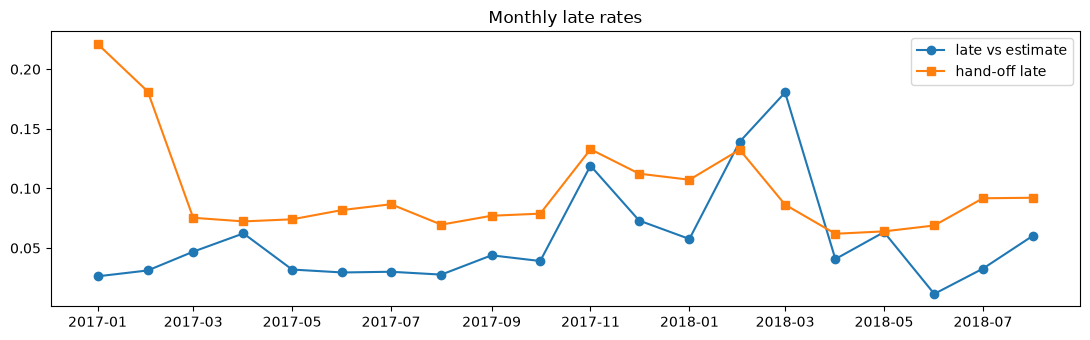

In [5]:
pm = con.execute("SELECT * FROM platform_month WHERE purchase_month BETWEEN '2017-01-01' AND '2018-08-01'").df()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(pm.purchase_month, pm.late_rate, 'o-', label='late vs estimate'); ax.plot(pm.purchase_month, pm.handoff_late_rate, 's-', label='hand-off late')
ax.legend(); ax.set_title('Monthly late rates'); plt.tight_layout(); pm[['purchase_month','n_items','late_rate','handoff_late_rate','median_delivery_days']].tail(10)

The Nov-2017 and Feb-Mar 2018 spikes hit all sellers at once - they are not seller-specific.

## Interval decomposition

In [6]:
con.execute('''SELECT ROUND(MEDIAN(approval_hours),1) approval_h, ROUND(MEDIAN(handoff_days),2) purchase_to_carrier_d,
ROUND(MEDIAN(carrier_transit_days),2) carrier_transit_d, ROUND(MEDIAN(delivery_days),2) purchase_to_customer_d,
ROUND(AVG(is_late::INT),4) late_rate, ROUND(AVG(is_handoff_late::INT),4) handoff_late_rate FROM fct_orders_delivered''').df()

,approval_h,purchase_to_carrier_d,carrier_transit_d,purchase_to_customer_d,late_rate,handoff_late_rate
0,0.3,2.2,7.1,10.22,0.0677,0.0906


In [7]:
con.execute('''SELECT is_handoff_late, COUNT(*) n, AVG(is_late::INT) late_rate, AVG(review_score) review
FROM fct_orders_delivered WHERE is_handoff_late IS NOT NULL GROUP BY 1''').df()

,is_handoff_late,n,late_rate,review
0,False,87581,0.053859,4.200832
1,True,8723,0.207956,3.699223


## Seller volume distribution (why shrinkage is needed)

In [8]:
s = con.execute('SELECT n_items, gmv FROM seller_summary').df()
print(s.n_items.describe(percentiles=[.25,.5,.75,.9,.99]).round(1))
print(f"sellers with <5 items: {(s.n_items<5).mean():.1%}; top 10% GMV share: {s.gmv.sort_values(ascending=False).head(int(len(s)*.1)).sum()/s.gmv.sum():.1%}")

count    3095.0
mean       36.4
std       119.2
min         1.0
25%         2.0
50%         8.0
75%        24.0
90%        80.0
99%       431.2
max      2033.0
Name: n_items, dtype: float64
sellers with <5 items: 38.8%; top 10% GMV share: 67.5%


## Window functions on the seller-month panel

In [9]:
con.execute('''SELECT seller_id, purchase_month, n_items, late_rate, late_rate_roll3, cum_items, gmv_rank_in_month
FROM seller_month_panel WHERE seller_id = (SELECT seller_id FROM seller_summary ORDER BY gmv DESC LIMIT 1)
ORDER BY purchase_month''').df().tail(8)

,seller_id,purchase_month,n_items,late_rate,late_rate_roll3,cum_items,gmv_rank_in_month
9,4869f7a5dfa277a7dca6462dcf3b52b2,2018-01-01,72,0.027778,0.113924,492.0,1
10,4869f7a5dfa277a7dca6462dcf3b52b2,2018-02-01,89,0.356322,0.151261,581.0,1
11,4869f7a5dfa277a7dca6462dcf3b52b2,2018-03-01,117,0.313043,0.251825,698.0,3
12,4869f7a5dfa277a7dca6462dcf3b52b2,2018-04-01,127,0.032000,0.217125,825.0,3
13,4869f7a5dfa277a7dca6462dcf3b52b2,2018-05-01,94,0.063830,0.137725,919.0,6
14,4869f7a5dfa277a7dca6462dcf3b52b2,2018-06-01,97,0.000000,0.031646,1016.0,2
15,4869f7a5dfa277a7dca6462dcf3b52b2,2018-07-01,54,0.000000,0.024590,1070.0,10
16,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-01,86,0.034884,0.012712,1156.0,3


## Freight and lanes

In [10]:
con.execute('''SELECT same_state, COUNT(*) n, MEDIAN(delivery_days) med_days, AVG(is_late::INT) late_rate,
MEDIAN(freight_to_price) med_freight_ratio FROM fct_orders_delivered GROUP BY 1''').df()

,same_state,n,med_days,late_rate,med_freight_ratio
0,True,34822,6.539942,0.044914,0.180871
1,False,61648,12.804120,0.080619,0.255043


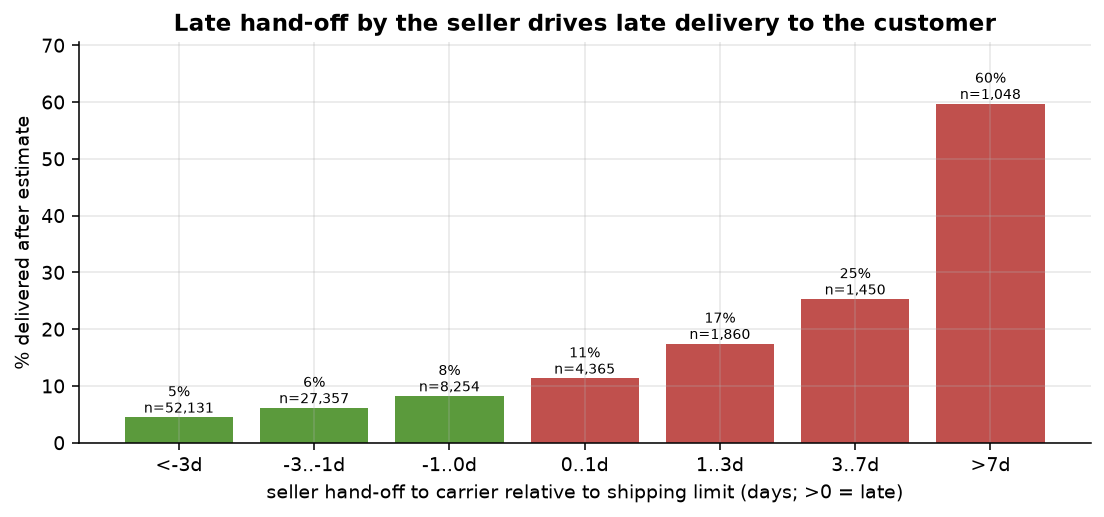

In [11]:
from IPython.display import Image; Image('docs/figures/handoff_delay_vs_late.png', width=700)